# Which signals rank fraud? Two routes to 0.95567

We rank transactions by their likelihood of fraud. Both private continuations of Malyshev Danil’s V43 scored **0.95567 public ROC AUC** on Kaggle, tying V43 and gaining **0.00007** over our V12 submission. The proposed quarter-step changes the median test rank by **101 places**, compared with **202** for the equally scoring capped half-step.

| Experiment | Kaggle public AUC | Δ vs. V12 | Decision |
|---|---:|---:|---|
| V12 · Step X reproduction | 0.95560 | — | Prior baseline |
| Step X + 5% digit-model residual | 0.95557 | −0.00003 | Drop |
| Malyshev Danil’s V43 | 0.95567 | +0.00007 | Source ranking |
| **V43 + 25% of the V42-to-V43 move** | **0.95567** | **+0.00007** | **Proposed file** |
| V43 + 50% of the move, capped at p99 | 0.95567 | +0.00007 | Tie with more rank movement |

The **0.95567** entries for our candidates come from the scored private experiment. Kaggle’s score badge on this notebook tracks submissions from this public notebook.

[Scored private experiment](https://www.kaggle.com/code/areebbb/s6e11-v43-correction-size?scriptVersionId=372981738) · [V43 source and upstream credits](https://www.kaggle.com/code/malyshevdanil/fraud-signal-lab-gpt-2-and-glm-fusion?scriptVersionId=372954959)


# Which signals rank fraud? Two routes to 0.95567

We rank transactions by their likelihood of fraud. Both private continuations of Malyshev Danil’s V43 scored **0.95567 public ROC AUC** on Kaggle, tying V43 and gaining **0.00007** over our V12 submission. The proposed quarter-step changes the median test rank by **101 places**, compared with **202** for the equally scoring capped half-step.

| Experiment | Kaggle public AUC | Δ vs. V12 | Decision |
|---|---:|---:|---|
| V12 · Step X reproduction | 0.95560 | — | Prior baseline |
| Step X + 5% digit-model residual | 0.95557 | −0.00003 | Drop |
| Malyshev Danil’s V43 | 0.95567 | +0.00007 | Source ranking |
| **V43 + 25% of the V42-to-V43 move** | **0.95567** | **+0.00007** | **Proposed file** |
| V43 + 50% of the move, capped at p99 | 0.95567 | +0.00007 | Tie with more rank movement |

The **0.95567** entries for our candidates come from the scored private experiment. Kaggle’s score badge on this notebook tracks submissions from this public notebook.

[Scored private experiment](https://www.kaggle.com/code/areebbb/s6e11-v43-correction-size?scriptVersionId=372981738) · [V43 source and upstream credits](https://www.kaggle.com/code/malyshevdanil/fraud-signal-lab-gpt-2-and-glm-fusion?scriptVersionId=372954959)


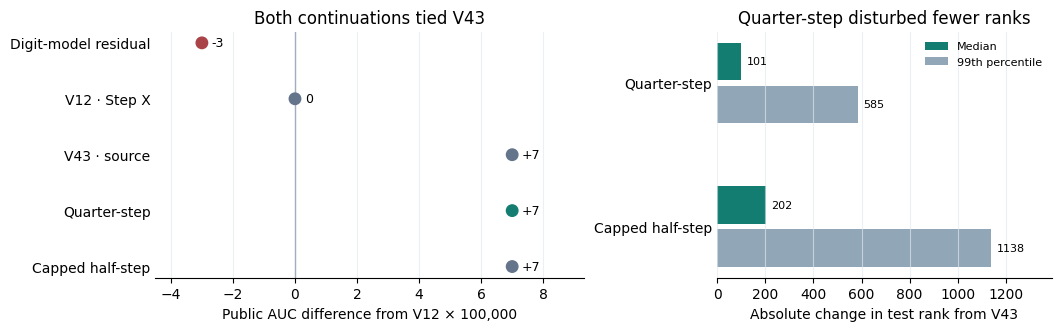

The left panel reports measured Kaggle scores. The right panel describes the magnitude of the prediction changes across the full test set. The score tie makes smaller rank displacement a practical reason to pick the quarter-step.

## What the experiments tell us

- **Promising direction.** V43 had already improved on V42. We tested continuing their difference in logit ranks, while preserving the existing low-risk block. The two step sizes earned the same displayed AUC. [V43 recipe and credits](https://www.kaggle.com/code/malyshevdanil/fraud-signal-lab-gpt-2-and-glm-fusion?scriptVersionId=372954959)
- **Failed transfer.** The 5% digit-model residual improved the XGBoost–TabM proxy by **0.0000763 pooled out-of-fold AUC**, with gains in all five folds. On Step X, its public score fell from **0.95560 to 0.95557**. A proxy that omits parts of the reference can favor a correction the reference has already captured. [Digit-model experiment](https://www.kaggle.com/code/areebbb/can-another-low-risk-region-improve-step-x?scriptVersionId=372840315)
- **Validation limits.** Exact V43 out-of-fold predictions were unavailable. The continuation comparison uses Kaggle’s scored public subset and the rank-movement diagnostic. The private leaderboard remains unknown.
- **Reproduce.** Run all cells with the competition data and the two attached public rank archives. The last section rebuilds the predictions, checks the 299,984 sample IDs, exact columns, probability bounds, and verifies the output SHA-256 against the scored quarter-step.

## Earlier experiments and the V12 baseline

The following historical cells document the original feature audit and Step X reproduction. The final section contains the current candidate recipe and writes the quarter-step CSV.


In [1]:
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np

display(Markdown("""# Which signals rank fraud? Two routes to 0.95567

We rank transactions by their likelihood of fraud. Both private continuations of Malyshev Danil’s V43 scored **0.95567 public ROC AUC** on Kaggle, tying V43 and gaining **0.00007** over our V12 submission. The proposed quarter-step changes the median test rank by **101 places**, compared with **202** for the equally scoring capped half-step.

| Experiment | Kaggle public AUC | Δ vs. V12 | Decision |
|---|---:|---:|---|
| V12 · Step X reproduction | 0.95560 | — | Prior baseline |
| Step X + 5% digit-model residual | 0.95557 | −0.00003 | Drop |
| Malyshev Danil’s V43 | 0.95567 | +0.00007 | Source ranking |
| **V43 + 25% of the V42-to-V43 move** | **0.95567** | **+0.00007** | **Proposed file** |
| V43 + 50% of the move, capped at p99 | 0.95567 | +0.00007 | Tie with more rank movement |

The **0.95567** entries for our candidates come from the scored private experiment. Kaggle’s score badge on this notebook tracks submissions from this public notebook.

[Scored private experiment](https://www.kaggle.com/code/areebbb/s6e11-v43-correction-size?scriptVersionId=372981738) · [V43 source and upstream credits](https://www.kaggle.com/code/malyshevdanil/fraud-signal-lab-gpt-2-and-glm-fusion?scriptVersionId=372954959)
"""))

labels = ["Digit-model residual", "V12 · Step X", "V43 · source", "Quarter-step", "Capped half-step"]
deltas = [-3, 0, 7, 7, 7]
fig, (score_ax, move_ax) = plt.subplots(1, 2, figsize=(10.5, 3.2),
    gridspec_kw={"width_ratios": [1.28, 1]}, layout="constrained")
score_ax.axvline(0, color="#a3aebc", linewidth=1)
score_ax.scatter(deltas, labels, s=68,
    c=["#a94347", "#64748b", "#64748b", "#147d71", "#64748b"], zorder=3)
for label, delta in zip(labels, deltas):
    score_ax.annotate(f"{delta:+d}" if delta else "0", (delta, label),
        xytext=(7, 0), textcoords="offset points", va="center", fontsize=9)
score_ax.invert_yaxis()
score_ax.set(xlim=(-4.5, 9.3), xlabel="Public AUC difference from V12 × 100,000",
    title="Both continuations tied V43")
y = np.arange(2)
for offset, values, label, color in [
    (-.15, [101, 202], "Median", "#147d71"),
    (.15, [585, 1138], "99th percentile", "#91a7b7"),
]:
    bars = move_ax.barh(y + offset, values, height=.26, label=label, color=color)
    move_ax.bar_label(bars, padding=4, fontsize=8)
move_ax.set(yticks=y, yticklabels=["Quarter-step", "Capped half-step"],
    xlim=(0, 1390), title="Quarter-step disturbed fewer ranks",
    xlabel="Absolute change in test rank from V43")
move_ax.invert_yaxis()
move_ax.legend(frameon=False, fontsize=8)
for axes in (score_ax, move_ax):
    axes.spines[["top", "right", "left"]].set_visible(False)
    axes.tick_params(axis="y", length=0)
    axes.grid(axis="x", color="#e2e8f0", zorder=0, alpha=.65)
plt.show()

display(Markdown("""The left panel reports measured Kaggle scores. The right panel describes the magnitude of the prediction changes across the full test set. The score tie makes smaller rank displacement a practical reason to pick the quarter-step.

## What the experiments tell us

- **Promising direction.** V43 had already improved on V42. We tested continuing their difference in logit ranks, while preserving the existing low-risk block. The two step sizes earned the same displayed AUC. [V43 recipe and credits](https://www.kaggle.com/code/malyshevdanil/fraud-signal-lab-gpt-2-and-glm-fusion?scriptVersionId=372954959)
- **Failed transfer.** The 5% digit-model residual improved the XGBoost–TabM proxy by **0.0000763 pooled out-of-fold AUC**, with gains in all five folds. On Step X, its public score fell from **0.95560 to 0.95557**. A proxy that omits parts of the reference can favor a correction the reference has already captured. [Digit-model experiment](https://www.kaggle.com/code/areebbb/can-another-low-risk-region-improve-step-x?scriptVersionId=372840315)
- **Validation limits.** Exact V43 out-of-fold predictions were unavailable. The continuation comparison uses Kaggle’s scored public subset and the rank-movement diagnostic. The private leaderboard remains unknown.
- **Reproduce.** Run all cells with the competition data and the two attached public rank archives. The last section rebuilds the predictions, checks the 299,984 sample IDs, exact columns, probability bounds, and verifies the output SHA-256 against the scored quarter-step.

## Earlier experiments and the V12 baseline

The following historical cells document the original feature audit and Step X reproduction. The final section contains the current candidate recipe and writes the quarter-step CSV.
"""))


## Feature audit

Which raw inputs can rank a fraudulent transaction above a legitimate one on their own? On a stratified 75/25 split, **merchant risk** led the numeric features with **0.74702** holdout AUC. **Velocity** followed at **0.70715**, then **CVV retry count** at **0.70223**. Amount alone reached **0.53905**.

For each feature, the training partition determines its missing-value replacement and whether higher or lower values indicate risk. We freeze both decisions before evaluating the holdout. This gives the chart a concrete interpretation: a gap between its two markers measures how the same ordering transferred to held-out transactions. This audit uses labels; the ensemble calculation below uses prediction files.

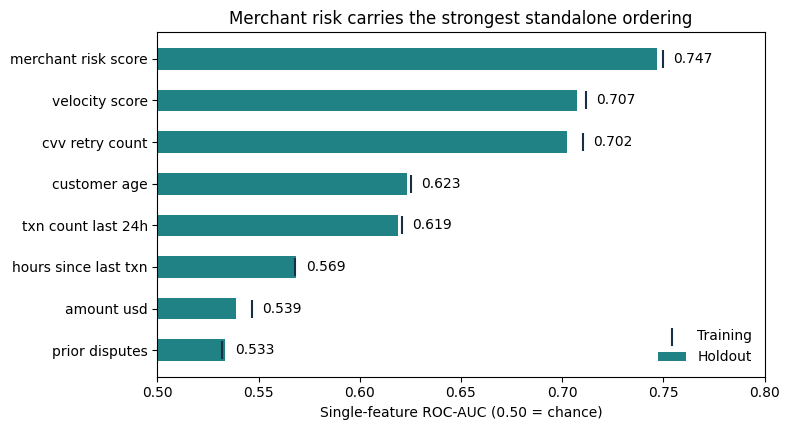

,feature,direction,training_auc,holdout_auc
8,merchant_risk_score,1,0.74957,0.74702
12,velocity_score,1,0.71200,0.70715
4,cvv_retry_count,1,0.71003,0.70223
3,customer_age,1,0.62525,0.62315
11,txn_count_last_24h,1,0.62082,0.61878
7,hours_since_last_txn,-1,0.56807,0.56865
1,amount_usd,1,0.54678,0.53905
9,prior_disputes,1,0.53174,0.53348
5,day_of_week,1,0.50819,0.50797
6,distance_from_home_km,1,0.50570,0.49838


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

root = Path('/kaggle/input')
paths = [p for p in root.rglob('train.csv') if 'playground-series-s6e11' in str(p)]
assert len(paths) == 1, paths
train = pd.read_csv(paths[0])
y = train.pop('is_fraud')
assert set(y.unique()) == {0, 1}
a, b = train_test_split(np.arange(len(y)), test_size=.25, random_state=42, stratify=y)
rows = []
for col in train.select_dtypes(include='number').columns.difference(['id']):
    x = train[col].replace([np.inf, -np.inf], np.nan)
    median = x.iloc[a].median()
    if pd.isna(median) or x.iloc[a].nunique() < 2:
        continue
    x = x.fillna(median)
    raw = roc_auc_score(y.iloc[a], x.iloc[a])
    sign = 1 if raw >= .5 else -1
    rows.append((col, sign, max(raw, 1-raw), roc_auc_score(y.iloc[b], sign*x.iloc[b])))
scores = pd.DataFrame(rows, columns=['feature','direction','training_auc','holdout_auc']).sort_values('training_auc', ascending=False)
assert len(scores), 'No eligible numeric feature'
top=scores.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8,4.4))
labels=top.feature.str.replace('_',' ')
ax.barh(labels,top.holdout_auc-.5,left=.5,color='#208285',height=.52,label='Holdout')
ax.scatter(top.training_auc,labels,marker='|',s=160,color='#172f45',label='Training')
for i,value in enumerate(top.holdout_auc):
    ax.text(max(value,top.training_auc.iloc[i])+.005,i,f'{value:.3f}',va='center')
ax.set_xlim(.5,.80)
ax.set(xlabel='Single-feature ROC-AUC (0.50 = chance)',title='Merchant risk carries the strongest standalone ordering')
ax.legend(frameon=False,loc='lower right')
fig.tight_layout()
plt.show()
display(scores.round(5))

## Reproducing Step X

goodpjw2008 took the earlier 0.95559 ranking, extended the earlier residual by 1.4, subtracted 0.3 times the move from step T to U, and reapplied the four low-risk regions. The author’s V35 earned 0.95560. We identify the original CSV by its full checksum and verify the sample IDs before copying it.

In [3]:
import hashlib, shutil
from scipy.stats import rankdata
expected='5c7e5518ac4beae1680675c585f006a7956d220338abf72a6951ae83f81579b8'
source=next(p for p in root.rglob('*.csv') if 'goodpjw' in str(p) and hashlib.sha256(p.read_bytes()).hexdigest()==expected)
sample=pd.read_csv(next(root.rglob('sample_submission.csv')))
frame=pd.read_csv(source)
assert list(frame.columns)==['id','is_fraud'] and len(frame)==299984
assert frame.id.equals(sample.id) and frame.id.is_unique and np.isfinite(frame.is_fraud).all()
output=Path('/kaggle/working/submission.csv')
shutil.copyfile(source,output)
print(len(frame),hashlib.sha256(output.read_bytes()).hexdigest())

299984 5c7e5518ac4beae1680675c585f006a7956d220338abf72a6951ae83f81579b8


## Probe results

| Private experiment | Public ROC-AUC |
|---|---:|
| Recent residual at 0.65 or 1.55 | 0.95558 each |
| Prior V7 residual alone or combined with the recent residual | 0.95558 each |
| Member correction or two recent steps combined | 0.95558 each |
| Recent residual plus earlier T − S residual | **0.95559** |

The six ties are at five-decimal precision. The final experiment changed two weights together, so these results do not isolate the benefit of either weight individually.

Public V9 added the independent P-to-Q move and scored **0.95559**, tying V8.

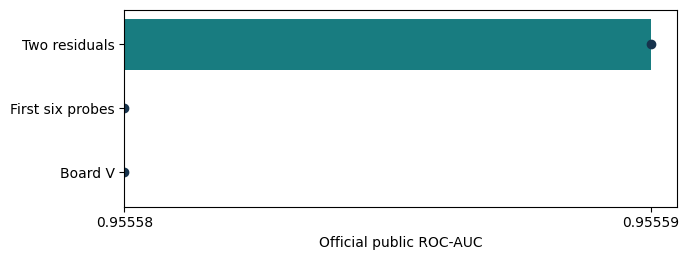

In [4]:
fig, ax=plt.subplots(figsize=(7,2.7))
ax.barh(['Board V','First six probes','Two residuals'],[0,0,1],color='#187c80')
ax.scatter([0,0,1],range(3),color='#17334d')
ax.set_xticks([0,1],['0.95558','0.95559'])
ax.set_xlabel('Official public ROC-AUC')
fig.tight_layout()
plt.show()

## Validation limits

The checksum verifies exact reproduction of the source prediction. The feature audit evaluates individual inputs. Private leaderboard performance is unknown.

## Credits

- [goodpjw2008 · Board Model + RealMLP](https://www.kaggle.com/code/goodpjw2008/s6e11-board-model-realmlp-lb-0-95558) supplies V and historical steps S, T and U, with upstream authors documented there.
- [Malyshev Danil · Fraud Signal Lab](https://www.kaggle.com/code/malyshevdanil/fraud-signal-lab-gpt-2-and-glm-fusion) supplies F.
- Areeb Ali designed and tested the two-residual combination. Kaggle supplies the competition data and official scores.
- **Current submission and Step X method: goodpjw2008.** All 299,984 predictions are from [Board Model + RealMLP, officially scored V35](https://www.kaggle.com/code/goodpjw2008/s6e11-board-model-realmlp-lb-0-95560?scriptVersionId=372663898). The source notebook documents the upstream model authors. Areeb Ali contributed the earlier V8 residual baseline, the feature audit and the reproduction checks.

# How much further can the V43 correction go?

Two versions of the same ranking idea each scored **0.95567 public ROC AUC** in our private notebook. Both tied Malyshev Danil’s V43 and improved on our earlier 0.95560. The proposed file uses the smaller step, which changed the median test-row rank by 101 places versus 202 for the capped half-step. The earlier sections document the V12 workflow.

| Experiment | Kaggle public ROC AUC | Δ vs. V12 | Decision |
|---|---:|---:|---|
| Our V12 reproduction of Step X | 0.95560 | — | Earlier reference |
| Step X + digit-model residual | 0.95557 | −0.00003 | Drop |
| Malyshev Danil’s V43 | 0.95567 | +0.00007 | Public reference |
| V43 + 25% of the V42-to-V43 move | 0.95567 | +0.00007 | Proposed file |
| V43 + 50% of the move, capped at p99 | 0.95567 | +0.00007 | Same displayed score, more movement |

### What we tested

We convert the V42 and V43 rankings to logit ranks, subtract V42 from V43, and add a fraction of that difference to V43. The four low-risk regions retain their internal order and stay below the other rows. V43, its recipe and the two scored-rank archives come from Malyshev Danil. The zone rules come from the credited upstream work in that notebook, including daoviet and Weni Mohamed. Our contribution here is the comparison of two continuation sizes and the exact output audit.

- [Malyshev Danil’s scored V43 and upstream credits](https://www.kaggle.com/code/malyshevdanil/fraud-signal-lab-gpt-2-and-glm-fusion?scriptVersionId=372954959)
- [Expanded ranking archive](https://www.kaggle.com/datasets/malyshevdanil/s6e11-nov21-expanded-public-frontier)
- [Additional ranking archive](https://www.kaggle.com/datasets/malyshevdanil/s6e11-nov23-round2-public-frontier)
- [Areeb Ali’s private V1 experiment](https://www.kaggle.com/code/areebbb/s6e11-v43-correction-size?scriptVersionId=372981738)

### What the scores establish

The continuation experiments used Kaggle’s public scorer. Exact out-of-fold predictions for V43 were unavailable, so we have no paired held-out AUC for these changes. In the earlier digit-model experiment, the proxy blend gained 0.0000763 across five validation folds, while the actual Step X submission dropped to 0.95557. That experiment illustrates the risk of transferring a proxy gain to an already strong ensemble. Here, the observed result is a tie at five-decimal precision. Private performance is unknown.

The chart measures rank displacement across the full test file. It explains why we chose the quarter-step given the score tie. The code independently rebuilds V43 and checks the new CSV against the exact bytes Kaggle scored from the private notebook.

VERIFIED QUARTER-STEP 299984 60ec5bd11eca0445c3b0b222a2715d3ffeee9594968cbce56061db16d87f5c62


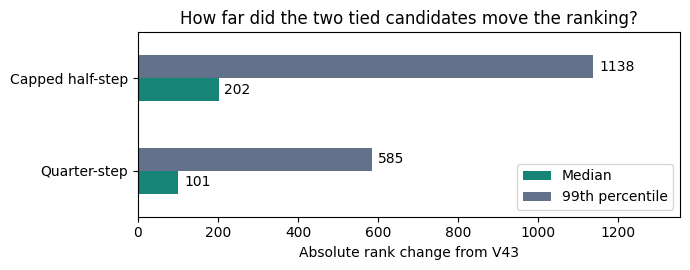

In [5]:
from IPython.display import Markdown, display
from scipy.special import logit
from scipy.stats import rankdata

display(Markdown("""# How much further can the V43 correction go?

Two versions of the same ranking idea each scored **0.95567 public ROC AUC** in our private notebook. Both tied Malyshev Danil’s V43 and improved on our earlier 0.95560. The proposed file uses the smaller step, which changed the median test-row rank by 101 places versus 202 for the capped half-step. The earlier sections document the V12 workflow.

| Experiment | Kaggle public ROC AUC | Δ vs. V12 | Decision |
|---|---:|---:|---|
| Our V12 reproduction of Step X | 0.95560 | — | Earlier reference |
| Step X + digit-model residual | 0.95557 | −0.00003 | Drop |
| Malyshev Danil’s V43 | 0.95567 | +0.00007 | Public reference |
| V43 + 25% of the V42-to-V43 move | 0.95567 | +0.00007 | Proposed file |
| V43 + 50% of the move, capped at p99 | 0.95567 | +0.00007 | Same displayed score, more movement |

### What we tested

We convert the V42 and V43 rankings to logit ranks, subtract V42 from V43, and add a fraction of that difference to V43. The four low-risk regions retain their internal order and stay below the other rows. V43, its recipe and the two scored-rank archives come from Malyshev Danil. The zone rules come from the credited upstream work in that notebook, including daoviet and Weni Mohamed. Our contribution here is the comparison of two continuation sizes and the exact output audit.

- [Malyshev Danil’s scored V43 and upstream credits](https://www.kaggle.com/code/malyshevdanil/fraud-signal-lab-gpt-2-and-glm-fusion?scriptVersionId=372954959)
- [Expanded ranking archive](https://www.kaggle.com/datasets/malyshevdanil/s6e11-nov21-expanded-public-frontier)
- [Additional ranking archive](https://www.kaggle.com/datasets/malyshevdanil/s6e11-nov23-round2-public-frontier)
- [Areeb Ali’s private V1 experiment](https://www.kaggle.com/code/areebbb/s6e11-v43-correction-size?scriptVersionId=372981738)

### What the scores establish

The continuation experiments used Kaggle’s public scorer. Exact out-of-fold predictions for V43 were unavailable, so we have no paired held-out AUC for these changes. In the earlier digit-model experiment, the proxy blend gained 0.0000763 across five validation folds, while the actual Step X submission dropped to 0.95557. That experiment illustrates the risk of transferring a proxy gain to an already strong ensemble. Here, the observed result is a tie at five-decimal precision. Private performance is unknown.

The chart measures rank displacement across the full test file. It explains why we chose the quarter-step given the score tie. The code independently rebuilds V43 and checks the new CSV against the exact bytes Kaggle scored from the private notebook."""))

from io import StringIO
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

inputs = Path("/kaggle/input")
files = next(p.parent for p in inputs.rglob("sample_submission.csv") if "playground-series-s6e11" in str(p))
sample = pd.read_csv(files / "sample_submission.csv")
test = pd.read_csv(files / "test.csv")
assert test.id.equals(sample.id) and sample.id.is_unique and len(sample) == 299984
with np.load(next(inputs.rglob("scored_rankings.npz")), allow_pickle=False) as archive:
    assert np.array_equal(archive["id"], sample.id)
    step_z = archive["Z"].copy() if "Z" in archive.files else None
with np.load(next(inputs.rglob("additional_scored_rankings.npz")), allow_pickle=False) as archive:
    assert np.array_equal(archive["id"], sample.id)
    v42 = archive["own_v42"].copy()
    if step_z is None:
        step_z = archive["Z"].copy()

def ranks(values):
    return (rankdata(values) - .5) / len(values)

def logit_ranks(values):
    assert np.isfinite(values).all()
    return logit(ranks(values))

def csv_text(probabilities):
    return sample.assign(is_fraud=probabilities).to_csv(index=False, lineterminator="\n")

flags = ["is_new_merchant", "is_foreign_transaction", "used_vpn", "ip_country_mismatch",
         "billing_shipping_mismatch", "is_ai_generated_scam_attempt"]
clean = test.cvv_retry_count.eq(0) & test.prior_disputes.eq(0) & ~test[flags].astype(bool).any(axis=1)
risk, velocity = test.merchant_risk_score, test.velocity_score
zones = ((risk < 13.1) | ((velocity <= 4.1) & (risk <= 20)) |
         (clean & (((velocity <= 4.1) & (risk <= 33.8)) | ((velocity <= 6) & (risk <= 25))))).to_numpy()
assert len(step_z) == len(v42) == len(sample)
v42_logit = logit_ranks(v42)
v43 = ranks(ranks(v42_logit - (logit_ranks(step_z) - v42_logit)) - 2 * zones)
encoded = csv_text(v43)
assert hashlib.sha256(encoded.encode()).hexdigest() == "5689d07cc601becb3b2530b87fa5c03241a79d54fb2aba10fe2773d6eaf0464c"
base = pd.read_csv(StringIO(encoded)).is_fraud.to_numpy()
base_logit = logit_ranks(base)
delta = base_logit - v42_logit
cap = np.quantile(np.abs(delta[~zones]), .99)
experiment = []
for name, weight, direction, expected in [
    ("Quarter-step", .25, delta, "60ec5bd11eca0445c3b0b222a2715d3ffeee9594968cbce56061db16d87f5c62"),
    ("Capped half-step", .50, np.clip(delta, -cap, cap), "0edfc94a483bc135adb658725fb4b9e81511dc8e9d76756c6caa5f1f46c368ba"),
]:
    score = base_logit.copy()
    score[~zones] += weight * direction[~zones]
    score[zones] -= 100
    assert score[zones].max() < score[~zones].min()
    np.testing.assert_array_equal(rankdata(score[zones]), rankdata(base_logit[zones]))
    output = csv_text(ranks(score))
    assert hashlib.sha256(output.encode()).hexdigest() == expected
    check = pd.read_csv(StringIO(output))
    assert check.columns.equals(sample.columns) and check.id.equals(sample.id)
    assert check.id.is_unique and len(check) == 299984 and check.is_fraud.between(0,1).all()
    movement = np.abs(rankdata(score) - rankdata(base))
    experiment.append((name, np.median(movement), np.quantile(movement, .99)))
    if name == "Quarter-step":
        path = Path("/kaggle/working/submission.csv")
        path.write_bytes(output.encode())
        assert hashlib.sha256(path.read_bytes()).hexdigest() == expected
        print("VERIFIED QUARTER-STEP", len(check), expected)
figure = pd.DataFrame(experiment, columns=["Candidate", "Median", "99th percentile"]).set_index("Candidate")
ax = figure.plot.barh(figsize=(7, 2.8), color=["#168476", "#63718a"])
ax.set(title="How far did the two tied candidates move the ranking?",
       xlabel="Absolute rank change from V43", ylabel="")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_xlim(0, figure.to_numpy().max() * 1.19)
plt.tight_layout()
plt.show()
